In [ ]:
import os
os.environ['KAGGLE_USERNAME'] = "xxxxxx"
os.environ['KAGGLE_KEY'] = "xxxxxx"

from kaggle.api.kaggle_api_extended import KaggleApi
api = KaggleApi()
api.authenticate()
api.dataset_download_files("Cornell-University/arxiv", path="data", unzip=True)

In [ ]:
import json
import time
import pandas as pd

""" Choosing global: You can choose to reasonably subsample the dataset, or to focus on specific sub-views
(provided that the code scales up with data, as described in the last section). In these
cases, it is advisable that a global variable is used to trigger either subsampling or the
use of the whole data."""

# GLOBAL VARIABLE

ROWS_LIMIT = 500_000 # can be set to None to load entire json file (which has ~3M rows)

t0 = time.perf_counter()

#loading data from json file of arxiv dataset
ids =[]
abstracts =[]
titles =[]
comments =[]
categories = []

with open("data/arxiv-metadata-oai-snapshot.json","r",encoding="utf-8") as f:
    for i, line in enumerate(f):
        if ROWS_LIMIT is not None and i >= ROWS_LIMIT:
            break
        paper = json.loads(line)
        ids.append(paper['id'])
        abstracts.append(paper['abstract'])
        titles.append(paper['title'])
        comments.append(paper['comments'])
        categories.append(paper['categories'])

#making a pandas dataframe
df = pd.DataFrame({'id': ids,'abstract': abstracts,'title': titles, 'comments': comments,'categories': categories})

print(f"Loading time: {time.perf_counter()-t0:.1f} s")
#print(df.shape)
df.head()

Loading time: 6.5 s


,id,abstract,title,comments,categories
0,0704.0001,A fully differential calculation in perturba...,Calculation of prompt diphoton production cros...,"37 pages, 15 figures; published version",hep-ph
1,0704.0002,"We describe a new algorithm, the $(k,\ell)$-...",Sparsity-certifying Graph Decompositions,To appear in Graphs and Combinatorics,math.CO cs.CG
2,0704.0003,The evolution of Earth-Moon system is descri...,The evolution of the Earth-Moon system based o...,"23 pages, 3 figures",physics.gen-ph
3,0704.0004,We show that a determinant of Stirling cycle...,A determinant of Stirling cycle numbers counts...,11 pages,math.CO
4,0704.0005,In this paper we show how to compute the $\L...,From dyadic $\Lambda_{\alpha}$ to $\Lambda_{\a...,NaN,math.CA math.FA


In [3]:
##To preprocess data, i decided to leave latex expressions as separate tokens, because there are datasets that have identical text 
## with only latex formulas being different. 

In [4]:
import re #regular expression library
import unicodedata  ## to normalize text


# my tokens where i save latex and math as tokens too
my_token = re.compile(
    r"(?P<math>\$(?=\S)(?:\\.|[^$\\]){1,200}?(?<=\S)\$(?!\d))" #for latex like $a+b$
    r"|(?P<cmd>\\[A-Za-z]+)"      #for simple latex like \Delta
    r"|(?P<word>\w+(?:[.'-]\w+)*)", #word/number
    re.DOTALL #to prevent from getting lost math expressions with newlines
)

def abstract_tokenized(text):
    text = unicodedata.normalize("NFKC", text)
    tokens =[]
    for token in my_token.finditer(text):
        if token.lastgroup== "word":
            tokens.append(token.group().lower())
        else:
            tokens.append(re.sub(r"\s+", "", token.group()))
    return tokens

In [5]:
t0 = time.perf_counter()
df['tokens']=df['abstract'].apply(abstract_tokenized)
print(f"Tokenization time: {time.perf_counter()-t0:.1f} s")

Tokenization time: 70.1 s


In [6]:
lengths = df['tokens'].apply(len)
lengths.describe()

count    500000.000000
mean        129.003066
std          65.175012
min           2.000000
25%          81.000000
50%         117.000000
75%         167.000000
max         555.000000
Name: tokens, dtype: float64

In [7]:
## Dropping abstracts that have less than 20 tokens. Thus empty or NaN absracts are also dropped

In [8]:
df = df[df['tokens'].apply(len)>= 20].copy() ##empty dropped too

In [9]:
len(df['tokens'])

495623

In [10]:
mask = df['comments'].str.contains(
    r'withdraw| withdrawn |withdrew |withdrawing | withdrawal',
    case=False,
    na=False
)

#print(mask.sum())
df = df[~mask].copy() #drop withdrawn articles based on comments, because an abstract can possible have the word withdraw in it properly
df = df.reset_index(drop=True) 

In [11]:
len(df)

492855

In [12]:
## Chosen encoding: k=3 word shingling
import numpy as np

k=3
vocab = {}
mult = np.random.default_rng(7).integers(1, 2**63, size=k, dtype=np.uint64) | np.uint64(1) 

def shingling(tokens):
    t = np.fromiter((vocab.setdefault(w, len(vocab)) for w in tokens),dtype=np.uint64, count=len(tokens))
    m = len(t)-k+1
    h = np.zeros(m, dtype=np.uint64)
    for j in range(k):
        h += t[j:j+m] * mult[j]    
    return np.unique(h)            # sorted unique ids  bein the set of shingles of the abstract

t0 = time.perf_counter()
shingle_sets = [shingling(tokens) for tokens in df['tokens']]   
print(f"Shingling time: {time.perf_counter()-t0:.1f} s")

Shingling time: 42.7 s


In [13]:
len(df['tokens'].iloc[0])

142

In [14]:
len(shingle_sets[0])
#before and after shingling lengths

140

In [15]:
#deleteing strings
df = df.drop(columns=['tokens'])
del vocab

### Minhash algorithm

In [16]:
#Choosing 128 as number of hash functions/signature length
n = 128
modulus = 2**31-1
rng = np.random.default_rng(42)

a = rng.integers(1, modulus, size=n,dtype=np.int64)
b = rng.integers(0, modulus,size=n,dtype=np.int64)

def minhash(shingle_ids):
    x = (shingle_ids % np.uint64(modulus)).astype(np.int64)      
    hashes = (a[:,None]*x[None, :]+ b[:, None]) % modulus    
    return hashes.min(axis=1)                                     

In [17]:
t0 = time.perf_counter()

sigs = np.empty((len(shingle_sets), n), dtype=np.uint32)   # signature matrix: one row per abstract
for i, shingle_ids in enumerate(shingle_sets):
    sigs[i] = minhash(shingle_ids)

print(f"MinHash time: {time.perf_counter()-t0:.1f} s")
minhash_time = time.perf_counter()-t0

MinHash time: 67.1 s


In [18]:
#print(sigs.shape)
#sigs[:3]

### LSH algorithm

In [19]:
#Choosing bands and rows for 128  as 32, 4:
bands=32
rows=4
assert bands*rows <= n

from itertools import combinations

max_bucket_size = None 

t0 = time.perf_counter()

candidate_pairs = set()
largest_bucket=0

for band in range(bands):
    block = sigs[:, band*rows:(band+1)*rows]
    # sort abstracts 
    order = np.lexsort(block.T[::-1])
    sorted_block = block[order]
    new_bucket = np.any(sorted_block[1:] != sorted_block[:-1], axis=1)
    starts = np.concatenate(([0], np.flatnonzero(new_bucket) + 1))
    ends = np.concatenate((starts[1:], [len(order)]))
    sizes = ends-starts
    largest_bucket = max(largest_bucket, sizes.max())

    #identifying candidates pairs
    for s, e in zip(starts[sizes > 1], ends[sizes > 1]):
        if max_bucket_size is not None and e - s > max_bucket_size:
            continue
        members = np.sort(order[s:e]).tolist()
        candidate_pairs.update(combinations(members, 2)) 

print(f"LSH time: {time.perf_counter()-t0:.1f} s")
print(f"Largest bucket: {largest_bucket}")
print(f"Number of candidate pairs: {len(candidate_pairs)}")
lsh_time = time.perf_counter()-t0

LSH time: 11.8 s
Largest bucket: 43
Number of candidate pairs: 9206


In [20]:
## JACCARD

In [21]:
def jaccard(set1, set2):
    inter = np.intersect1d(set1, set2, assume_unique=True).size  
    union = len(set1) + len(set2) - inter
    return inter / union if union else 0

chosen_threshold =0.5
similar_pairs =[]

t0 = time.perf_counter()

for i, j in candidate_pairs:
    score = jaccard(shingle_sets[i], shingle_sets[j])
    if score >=chosen_threshold:
        similar_pairs.append((i, j,score))

print(f"Jaccard time: {time.perf_counter()-t0:.1f} s")
print(f"Number of abstracts: {len(df)}")
#print(f"Number of candidate pairs: {len(candidate_pairs)}")
print(f"Number of similar pairs where Jaccard similarity >= {chosen_threshold} is: {len(similar_pairs)} pairs")

Jaccard time: 0.1 s
Number of abstracts: 492855
Number of similar pairs where Jaccard similarity >= 0.5 is: 3704 pairs


In [22]:
#looking at results to imprive code/for report

#for i, j, score in sorted(similar_pairs, key=lambda x: x[2], reverse=True):
 #   print(f"\nJaccard similarity score: {score:.3f}")
  #  print(f"First paper: {df.iloc[i]['id']}, TITLE: {df.iloc[i]['title']},\n ABSTRACT: {df.iloc[i]['abstract']}")
   # print(f"Second paper: {df.iloc[j]['id']}, TITLE: {df.iloc[j]['title']},\n ABSTRACT: {df.iloc[j]['abstract']}")
    #print("*"*100)"""

In [23]:
#comparing algorithm performance

comparisons=[]

for i, j, jac_score in similar_pairs:
    minhash_score = np.mean(sigs[i]==sigs[j])

    comparisons.append({
        'id_1': df['id'].iloc[i],
        'id_2': df['id'].iloc[j],
        'jaccard': jac_score,
        'minhash': minhash_score,
        'absolute_error': abs(jac_score - minhash_score)
    })

comp_df = pd.DataFrame(comparisons)

comp_df.sort_values('jaccard', ascending=False)

,id_1,id_2,jaccard,minhash,absolute_error
1348,0704.2161,0901.1560,1.0,1.000000,0.000000
1361,1106.1762,1308.4793,1.0,1.000000,0.000000
1299,1202.2766,1202.4352,1.0,1.000000,0.000000
1300,0704.2411,1004.4578,1.0,1.000000,0.000000
1302,0710.5081,0710.5084,1.0,1.000000,0.000000
...,...,...,...,...,...
3611,0904.2362,1203.1194,0.5,0.539062,0.039062
2797,1302.2651,1309.4649,0.5,0.484375,0.015625
3622,0809.3886,0811.0863,0.5,0.453125,0.046875
1385,0912.1025,1006.3952,0.5,0.562500,0.062500


In [24]:
print("Mean absolute error:", comp_df['absolute_error'].mean())
print("Median absolute error:", comp_df['absolute_error'].median())
print("Maximum absolute error:", comp_df['absolute_error'].max())

Mean absolute error: 0.027423238158497332
Median absolute error: 0.02103225973487982
Maximum absolute error: 0.22829861111111116


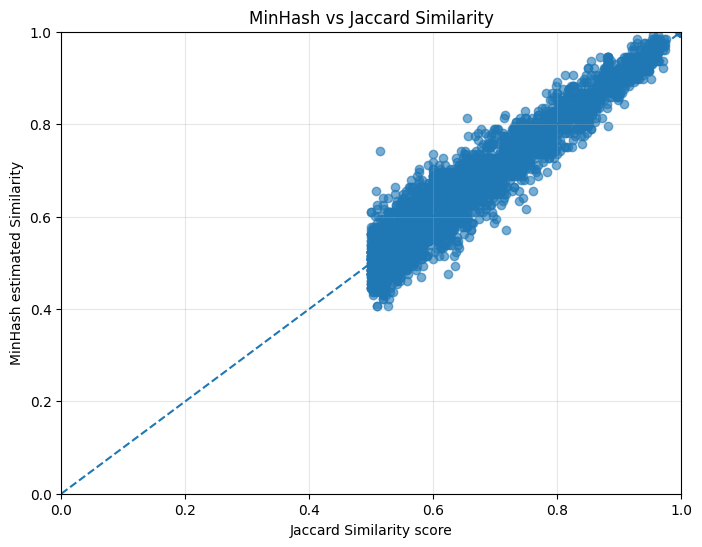

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(comp_df['jaccard'],comp_df['minhash'],alpha=0.6)
# line
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel('Jaccard Similarity score')
plt.ylabel('MinHash estimated Similarity')
plt.title('MinHash vs Jaccard Similarity')

plt.xlim(0,1)
plt.ylim(0,1)
plt.grid(alpha=0.3)

plt.show()

In [26]:
print(f'Time spent on MinHashing for 500_000 abstracts: {minhash_time} s')
print(f'Time spent on LSH for 500_000 abstracts: {lsh_time} s')

Time spent on MinHashing for 500_000 abstracts: 67.08482270000968 s
Time spent on LSH for 500_000 abstracts: 11.842483700020239 s
